In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [29]:
file_path = "../data/processed/daily_consumption.csv"
df = pd.read_csv(
    file_path,
    index_col=0,
    parse_dates=True
)
df.index.name = "datetime"
display(df.head())
print(df.shape)

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-17,56.507667,0.156949,240.087028,9.999028,2033.0,4187.0,13341.0
2006-12-18,36.730433,0.112356,241.231694,6.421667,1063.0,2621.0,14018.0
2006-12-19,27.769900,0.104821,241.999312,4.926389,839.0,7602.0,6197.0
2006-12-20,37.095800,0.111804,242.308063,6.467361,0.0,2648.0,14063.0
2006-12-21,28.618567,0.100115,241.041903,5.028194,1765.0,2623.0,10421.0


(1440, 7)


### Preparingf forecasting features

In [30]:
# Extract calendar features
df["day_of_week"] = df.index.dayofweek
df["month"] = df.index.month
df["day_of_year"] = df.index.dayofyear

# Historical consumption features
df["lag_1"] = df["Global_active_power"].shift(1)
df["lag_7"] = df["Global_active_power"].shift(7)

# Average consumption over the previous 7 days
df["rolling_mean_7"] = (
    df["Global_active_power"]
    .shift(1)
    .rolling(window=7)
    .mean()
)

# Remove rows without sufficient historical data
df.dropna(inplace=True)

df.head()

C:\Users\HP\AppData\Local\Temp\ipykernel_5524\132189444.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df["day_of_week"] = df.index.dayofweek
C:\Users\HP\AppData\Local\Temp\ipykernel_5524\132189444.py:4: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  df["day_of_year"] = df.index.dayofyear
C:\Users\HP\AppData\Local\Temp\ipykernel_5524\132189444.py:19: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace=True)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,day_of_week,month,day_of_year,lag_1,lag_7,rolling_mean_7
datetime,,,,,,,,,,,,,
2006-12-24,42.500200,0.104097,241.687437,7.640417,1703.0,5082.0,6891.0,6,12,358,79.556433,56.507667,43.614443
2006-12-25,45.718667,0.166861,243.399931,7.951528,6620.0,1962.0,5795.0,0,12,359,42.500200,36.730433,41.613376
2006-12-26,65.568500,0.114654,241.625438,11.347917,1086.0,2533.0,14979.0,1,12,360,45.718667,27.769900,42.897410
2006-12-27,25.479333,0.124238,243.767361,4.517500,0.0,314.0,6976.0,2,12,361,65.568500,37.095800,48.297210
2006-12-28,34.543967,0.145053,243.268333,6.086250,2207.0,4419.0,9176.0,3,12,362,25.479333,28.618567,46.637714


### Separate features and target

In [31]:
X = df[
    [
        "day_of_week",
        "month",
        "day_of_year",
        "lag_1",
        "lag_7",
        "rolling_mean_7"
    ]
]

y = df["Global_active_power"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1433, 6)
Target shape: (1433,)


### Split training and testing data

In [32]:
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1146
Testing records: 287


### Train our first machine learning model

In [33]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


### Make predictions

In [34]:
y_pred = model.predict(X_test)

predictions = pd.DataFrame({
    "Actual Consumption": y_test,
    "Predicted Consumption": y_pred
})

predictions.head(10)

,Actual Consumption,Predicted Consumption
datetime,,
2010-02-12,31.549967,31.645029
2010-02-13,39.192600,35.102377
2010-02-14,28.141667,35.785779
2010-02-15,34.952200,29.605469
2010-02-16,29.962600,31.180315
2010-02-17,34.242667,29.283013
2010-02-18,29.352600,30.453733
2010-02-19,32.559533,31.263430
2010-02-20,33.062133,33.519354


### Evaluate model performance

In [35]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("MODEL PERFORMANCE")
print("-------------------------")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))

MODEL PERFORMANCE
-------------------------
MAE: 4.303
RMSE: 5.955
R2 Score: 0.369


### Visualize actual versus predicted consumption

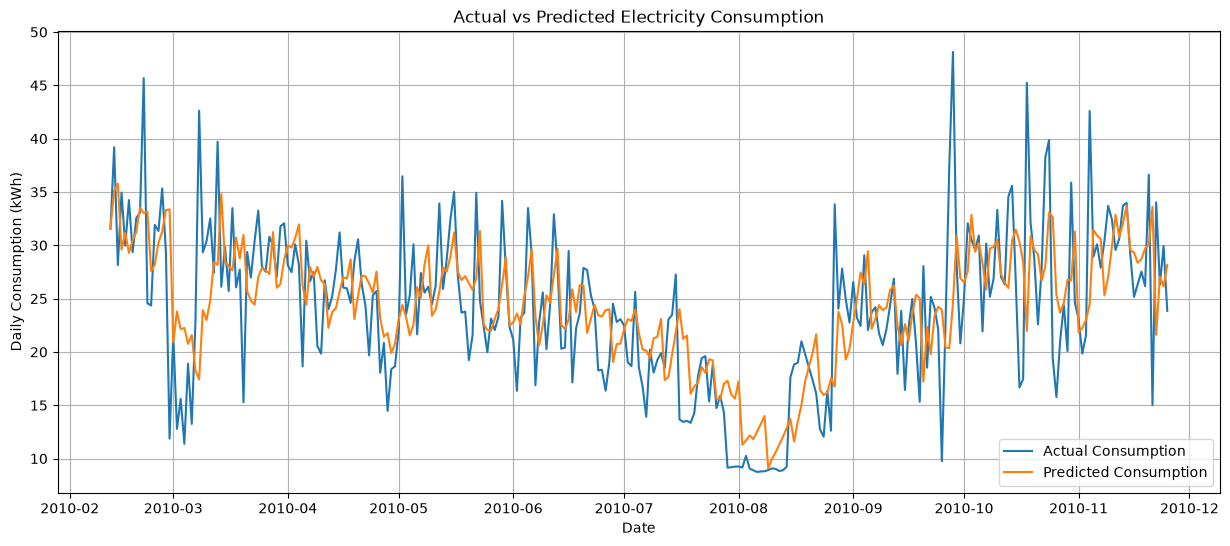

In [36]:
plt.figure(figsize=(15, 6))

plt.plot(y_test.index, y_test.values, label="Actual Consumption")
plt.plot(y_test.index, y_pred, label="Predicted Consumption")

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Daily Consumption (kWh)")

plt.legend()
plt.grid(True)
plt.show()

# Random Forest

In [37]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


### Making prediction

In [38]:
rf_predictions = rf_model.predict(X_test)

### Evaluating perfomance

In [39]:
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(y_test, rf_predictions)

print("RANDOM FOREST PERFORMANCE")
print("--------------------------")
print("MAE:", round(rf_mae, 3))
print("RMSE:", round(rf_rmse, 3))
print("R2 Score:", round(rf_r2, 3))

RANDOM FOREST PERFORMANCE
--------------------------
MAE: 4.135
RMSE: 5.685
R2 Score: 0.425


### Visualize predictions

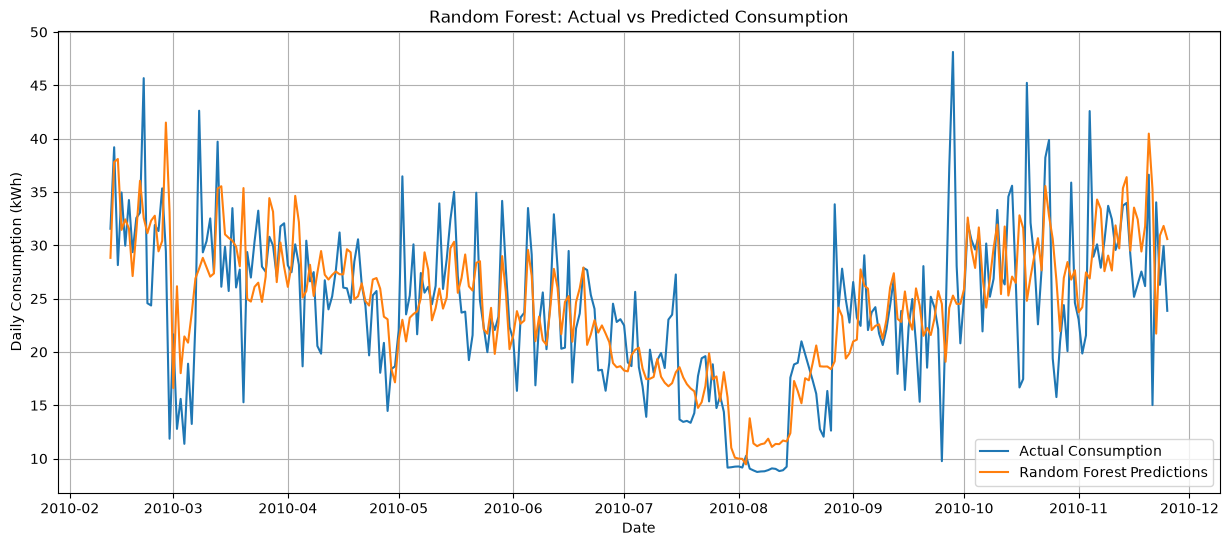

In [40]:
plt.figure(figsize=(15, 6))

plt.plot(y_test.index, y_test.values,
         label="Actual Consumption")

plt.plot(y_test.index, rf_predictions,
         label="Random Forest Predictions")

plt.title("Random Forest: Actual vs Predicted Consumption")
plt.xlabel("Date")
plt.ylabel("Daily Consumption (kWh)")

plt.legend()
plt.grid(True)
plt.show()

### Compare our models

In [41]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R2 Score": [r2, rf_r2]
})

display(comparison)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,4.303451,5.954518,0.368847
1,Random Forest,4.135470,5.684918,0.424706


# XGBoost

In [42]:
from xgboost import XGBRegressor

print("XGBoost imported successfully!")


xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

XGBoost imported successfully!


### train the model

In [43]:
xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


### Make predictions

In [44]:
xgb_predictions = xgb_model.predict(X_test)

### Evaluate performance

In [45]:
xgb_mae = mean_absolute_error(y_test, xgb_predictions)

xgb_rmse = np.sqrt(
    mean_squared_error(y_test, xgb_predictions)
)

xgb_r2 = r2_score(y_test, xgb_predictions)

print("XGBOOST PERFORMANCE")
print("--------------------")
print("MAE:", round(xgb_mae, 3))
print("RMSE:", round(xgb_rmse, 3))
print("R2 Score:", round(xgb_r2, 3))

XGBOOST PERFORMANCE
--------------------
MAE: 4.088
RMSE: 5.725
R2 Score: 0.417


### Compare all three models

In [46]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],
    "MAE": [mae, rf_mae, xgb_mae],
    "RMSE": [rmse, rf_rmse, xgb_rmse],
    "R2 Score": [r2, rf_r2, xgb_r2]
})

display(comparison)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,4.303451,5.954518,0.368847
1,Random Forest,4.135470,5.684918,0.424706
2,XGBoost,4.087904,5.724731,0.416620


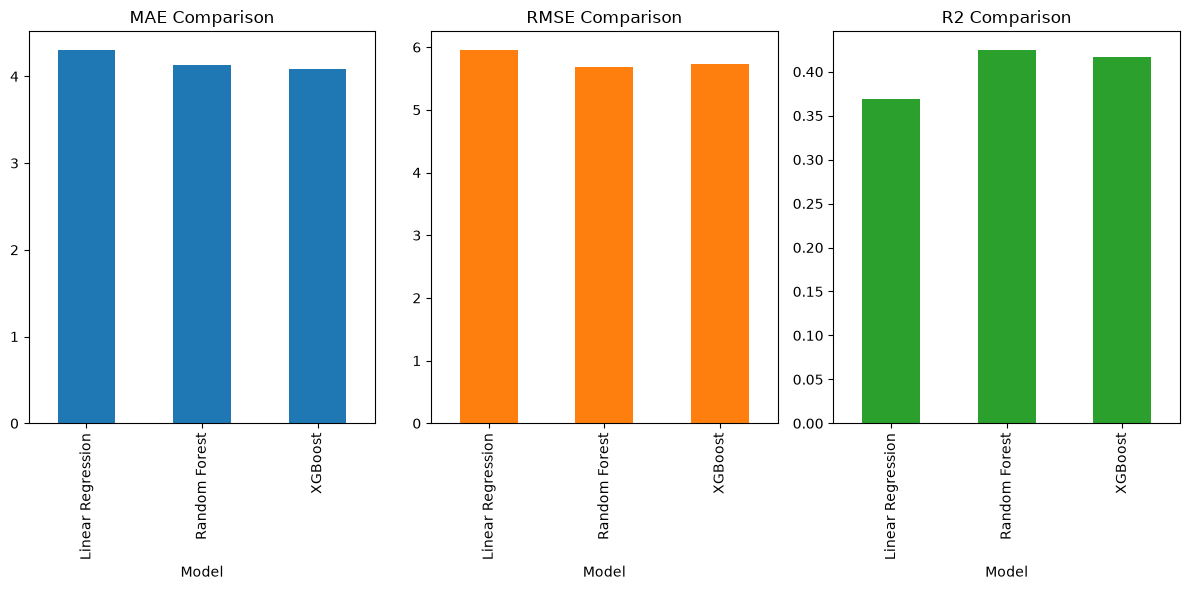

In [47]:
comparison.set_index("Model")[
    ["MAE", "RMSE", "R2 Score"]
].plot(
    kind="bar",
    figsize=(12, 6),
    subplots=True,
    layout=(1, 3),
    legend=False,
    title=["MAE Comparison", "RMSE Comparison", "R2 Comparison"]
)

plt.tight_layout()
plt.show()

# Model Optimization

In [48]:
# Predict tomorrow's consumption using yesterday's consumption
baseline_predictions = X_test["lag_1"].values

baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test, baseline_predictions
)

print("NAIVE BASELINE PERFORMANCE")
print("---------------------------")
print("MAE:", round(baseline_mae, 3))
print("RMSE:", round(baseline_rmse, 3))
print("R2 Score:", round(baseline_r2, 3))

NAIVE BASELINE PERFORMANCE
---------------------------
MAE: 4.906
RMSE: 6.865
R2 Score: 0.161


In [49]:
comparison = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],
    "MAE": [
        baseline_mae, mae, rf_mae, xgb_mae
    ],
    "RMSE": [
        baseline_rmse, rmse, rf_rmse, xgb_rmse
    ],
    "R2 Score": [
        baseline_r2, r2, rf_r2, xgb_r2
    ]
})

display(comparison)

,Model,MAE,RMSE,R2 Score
0,Naive Baseline,4.906056,6.865482,0.160958
1,Linear Regression,4.303451,5.954518,0.368847
2,Random Forest,4.135470,5.684918,0.424706
3,XGBoost,4.087904,5.724731,0.416620


### Hyperparameter tuning

In [50]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor

#Define the parameter combinations
param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [5, 10, 15, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [0.7, 1.0]
}

### Configure time-series cross-validation

In [51]:
tscv = TimeSeriesSplit(n_splits=5)

rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=20,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

### : Train and search for the best parameters

In [52]:
random_search.fit(X_train, y_train)

print("Best parameters:")
print(random_search.best_params_)

print("\nBest validation MAE:")
print(-random_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters:
{'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 0.7, 'max_depth': 20}

Best validation MAE:
5.22340532138862


### Evaluate the optimized model

In [53]:
best_rf = random_search.best_estimator_

tuned_predictions = best_rf.predict(X_test)

tuned_mae = mean_absolute_error(
    y_test, tuned_predictions
)

tuned_rmse = np.sqrt(
    mean_squared_error(y_test, tuned_predictions)
)

tuned_r2 = r2_score(
    y_test, tuned_predictions
)

print("TUNED RANDOM FOREST PERFORMANCE")
print("--------------------------------")
print("MAE:", round(tuned_mae, 3))
print("RMSE:", round(tuned_rmse, 3))
print("R2 Score:", round(tuned_r2, 3))

TUNED RANDOM FOREST PERFORMANCE
--------------------------------
MAE: 3.995
RMSE: 5.582
R2 Score: 0.445


# Future electricity consumption forecasting
- redict electricity consumption for the next 7 days without knowing the actual consumption during those seven days.

### check date continuity

In [55]:
date_gaps = df.index.to_series().diff().dropna()

print("Number of gaps greater than one day:",
      (date_gaps > pd.Timedelta(days=1)).sum())

print("Largest date gap:", date_gaps.max())

Number of gaps greater than one day: 0
Largest date gap: 1 days 00:00:00


### Create a seven-day forecasting function

In [60]:
def forecast_next_days(model, historical_data, days=7):

    history = list(
        historical_data["Global_active_power"].values
    )

    last_date = historical_data.index[-1]

    forecasts = []

    for i in range(1, days + 1):

        future_date = last_date + pd.Timedelta(days=i)

        features = pd.DataFrame([{
            "day_of_week": future_date.dayofweek,
            "month": future_date.month,
            "day_of_year": future_date.dayofyear,
            "lag_1": history[-1],
            "lag_7": history[-7],
            "rolling_mean_7": np.mean(history[-7:])
        }])

        prediction = model.predict(features)[0]

        # Prevent physically impossible negative consumption
        prediction = max(0, prediction)

        forecasts.append({
            "Date": future_date,
            "Predicted_Consumption_kWh": prediction
        })

        history.append(prediction)

    return pd.DataFrame(forecasts).set_index("Date")

In [62]:
forecast_history = df.iloc[:split_index]

future_forecast = forecast_next_days(
    best_rf,
    forecast_history,
    days=7
)

display(future_forecast)

C:\Users\HP\AppData\Local\Temp\ipykernel_5524\2130293399.py:16: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "day_of_week": future_date.dayofweek,
C:\Users\HP\AppData\Local\Temp\ipykernel_5524\2130293399.py:18: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  "day_of_year": future_date.dayofyear,
C:\Users\HP\AppData\Local\Temp\ipykernel_5524\2130293399.py:16: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "day_of_week": future_date.dayofweek,
C:\Users\HP\AppData\Local\Temp\ipykernel_5524\2130293399.py:18: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  "day_of_year": future_date.dayofyear,
C:\Users\HP\AppData\Local\Temp\ipykernel_5524\2130293399.py:16: Pandas4Warning: 

,Predicted_Consumption_kWh
Date,
2010-02-12,30.903607
2010-02-13,38.873759
2010-02-14,36.656469
2010-02-15,33.615687
2010-02-16,33.699718
2010-02-17,31.482530
2010-02-18,27.148424


### Visualize the forecast

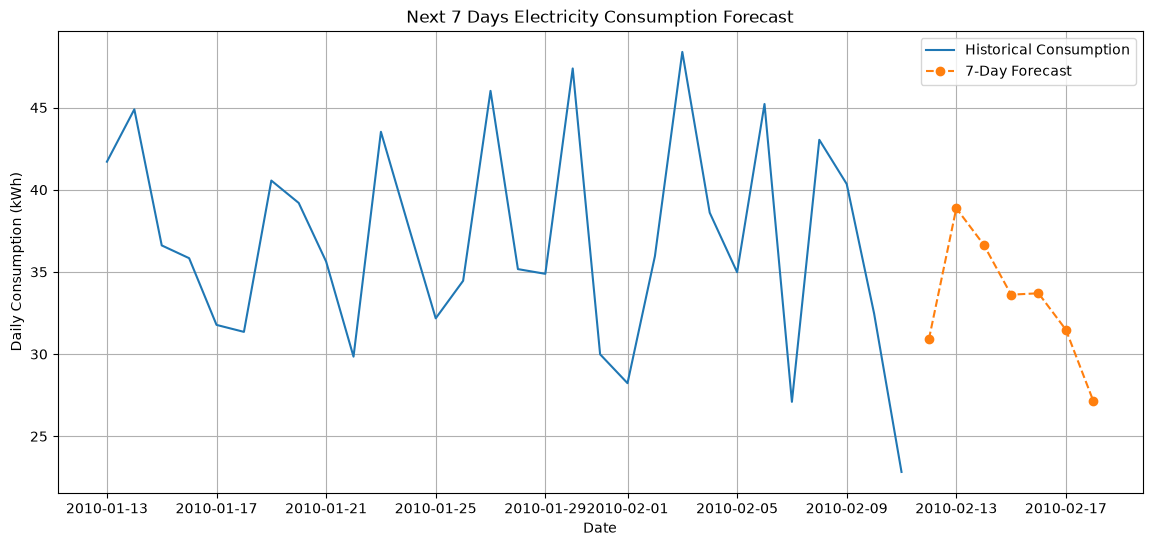

In [61]:
plt.figure(figsize=(14, 6))

plt.plot(
    forecast_history.index[-30:],
    forecast_history["Global_active_power"].tail(30),
    label="Historical Consumption"
)

plt.plot(
    future_forecast.index,
    future_forecast["Predicted_Consumption_kWh"],
    marker="o",
    linestyle="--",
    label="7-Day Forecast"
)

plt.title("Next 7 Days Electricity Consumption Forecast")
plt.xlabel("Date")
plt.ylabel("Daily Consumption (kWh)")
plt.legend()
plt.grid(True)
plt.show()

### Save the forecast

In [63]:
future_forecast.to_csv(
    "../data/processed/7_day_forecast.csv"
)

print("7-day forecast saved successfully!")

7-day forecast saved successfully!


### Evaluate the 7-day forecast

In [64]:
# Get actual consumption for the forecast dates
actual_next_7 = y_test.loc[future_forecast.index]

# Combine actual and predicted values
forecast_comparison = pd.DataFrame({
    "Actual": actual_next_7,
    "Predicted": future_forecast[
        "Predicted_Consumption_kWh"
    ]
})

forecast_comparison["Error"] = (
    forecast_comparison["Actual"]
    - forecast_comparison["Predicted"]
)

display(forecast_comparison)

,Actual,Predicted,Error
2010-02-12,31.549967,30.903607,0.646359
2010-02-13,39.192600,38.873759,0.318841
2010-02-14,28.141667,36.656469,-8.514803
2010-02-15,34.952200,33.615687,1.336513
2010-02-16,29.962600,33.699718,-3.737118
2010-02-17,34.242667,31.482530,2.760137
2010-02-18,29.352600,27.148424,2.204176


### Calculate forecasting accuracy

In [65]:
forecast_mae = mean_absolute_error(
    forecast_comparison["Actual"],
    forecast_comparison["Predicted"]
)

forecast_rmse = np.sqrt(
    mean_squared_error(
        forecast_comparison["Actual"],
        forecast_comparison["Predicted"]
    )
)

print("7-DAY FORECAST PERFORMANCE")
print("--------------------------")
print("MAE:", round(forecast_mae, 3))
print("RMSE:", round(forecast_rmse, 3))

7-DAY FORECAST PERFORMANCE
--------------------------
MAE: 2.788
RMSE: 3.803


### Visualize actual versus forecasted consumption

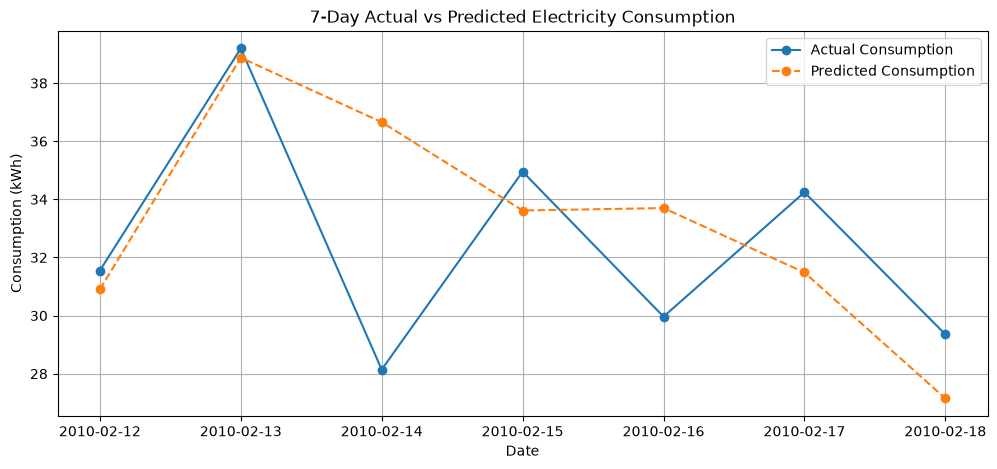

In [67]:
plt.figure(figsize=(12, 5))

plt.plot(
    forecast_comparison.index,
    forecast_comparison["Actual"],
    marker="o",
    label="Actual Consumption"
)

plt.plot(
    forecast_comparison.index,
    forecast_comparison["Predicted"],
    marker="o",
    linestyle="--",
    label="Predicted Consumption"
)

plt.title("7-Day Actual vs Predicted Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Consumption (kWh)")
plt.legend()
plt.grid(True)
plt.show()

# 30-day electricity consumption forecasting 

### Retrain the best model

In [68]:
from sklearn.base import clone

# Copy the optimized model configuration
final_model = clone(best_rf)

# Train using all available historical data
final_model.fit(X, y)

print("Final Random Forest model trained successfully!")

Final Random Forest model trained successfully!


### Generate a 30-day forecast

In [69]:
forecast_30_days = forecast_next_days(
    model=final_model,
    historical_data=df,
    days=30
)

display(forecast_30_days)

C:\Users\HP\AppData\Local\Temp\ipykernel_5524\2130293399.py:16: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "day_of_week": future_date.dayofweek,
C:\Users\HP\AppData\Local\Temp\ipykernel_5524\2130293399.py:18: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  "day_of_year": future_date.dayofyear,
C:\Users\HP\AppData\Local\Temp\ipykernel_5524\2130293399.py:16: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "day_of_week": future_date.dayofweek,
C:\Users\HP\AppData\Local\Temp\ipykernel_5524\2130293399.py:18: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  "day_of_year": future_date.dayofyear,
C:\Users\HP\AppData\Local\Temp\ipykernel_5524\2130293399.py:16: Pandas4Warning: 

,Predicted_Consumption_kWh
Date,
2010-11-26,29.182479
2010-11-27,36.687616
2010-11-28,36.048334
2010-11-29,28.737629
2010-11-30,30.252104
2010-12-01,30.800319
2010-12-02,29.221432
2010-12-03,31.854227
2010-12-04,36.062284


### Visualize the 30-day forecast

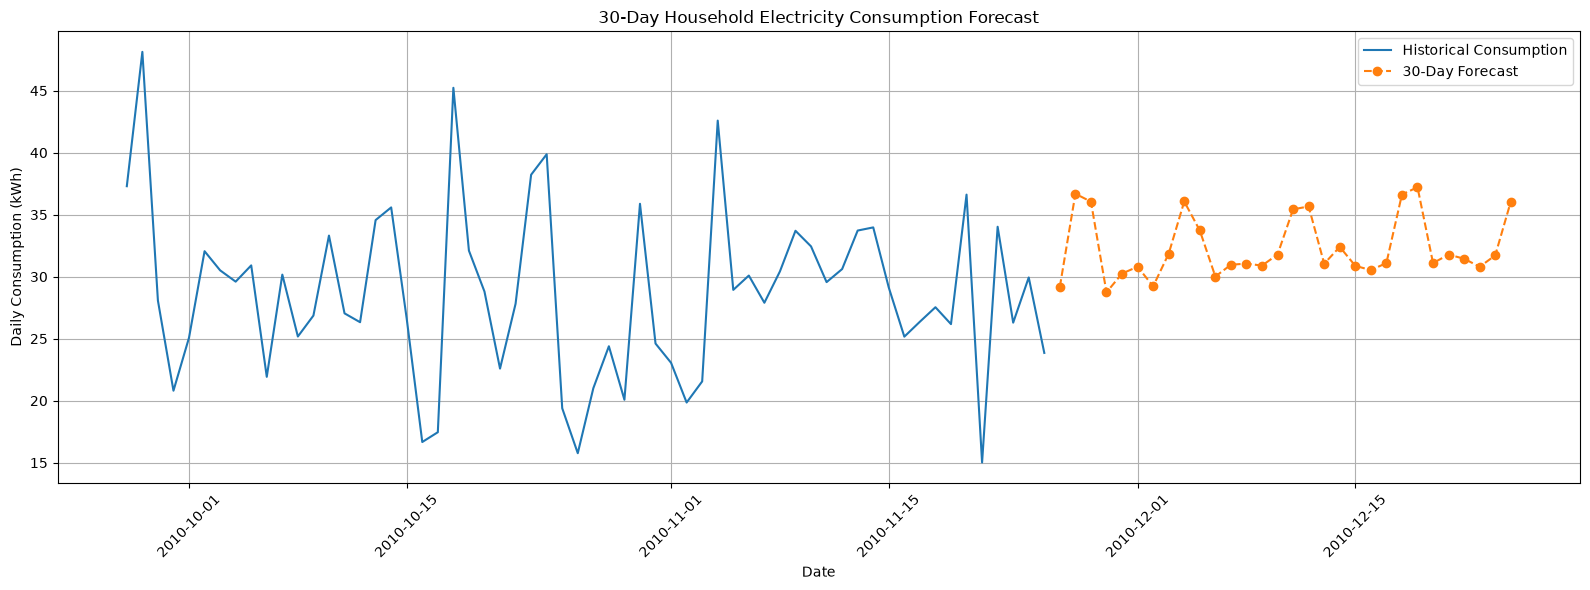

In [70]:
plt.figure(figsize=(16, 6))

# Last 60 days of historical consumption
plt.plot(
    df.index[-60:],
    df["Global_active_power"].tail(60),
    label="Historical Consumption"
)

# Future predictions
plt.plot(
    forecast_30_days.index,
    forecast_30_days["Predicted_Consumption_kWh"],
    marker="o",
    linestyle="--",
    label="30-Day Forecast"
)

plt.title("30-Day Household Electricity Consumption Forecast")
plt.xlabel("Date")
plt.ylabel("Daily Consumption (kWh)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Save the forecast

In [72]:
forecast_30_days.to_csv(
    "../data/processed/30_day_forecast.csv"
)

print("30-day forecast saved successfully!")

30-day forecast saved successfully!


# Save the trained model

In [73]:
import joblib

joblib.dump(
    final_model,
    "../models/random_forest_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [74]:
import joblib

# Save the feature names used during training
joblib.dump(
    list(X.columns),
    "../models/model_features.pkl"
)

print("Model features saved successfully!")

Model features saved successfully!
